# FloodQAOA — reproducible demo (one instance, ~1 minute)
**Qiskit Fall Fest 2026 · Disaster Response** · Team: Baqir Raza, M. Ali Reza, Balaaj Raza

Dispatch 3 relief teams to 4 flooded sites in Sindh (2022 floods) trading off **people reached** vs **response time**. This notebook: (1) builds the QUBO/Ising model, (2) runs constraint-preserving XY-CVaR-QAOA in Qiskit, (3) checks the answer against exact brute force.

In [1]:
import numpy as np
from floodqaoa.scenario import load_scenario, all_bitstrings
from floodqaoa.baseline import enumerate_feasible, normalisers, scalarised, pareto_mask
from floodqaoa.formulation import penalty_program, to_ising
from floodqaoa.qaoa import run_variant, VARIANTS

sc = load_scenario('data/sindh_2022.json')
f1max, f2max = normalisers(sc)
print(sc.T, 'teams x', sc.S, 'sites =', sc.n, 'qubits')
print('benefit (k people-equiv):'); print(sc.benefit.round(1))
print('travel (h):'); print(sc.travel_h.round(2))

3 teams x 4 sites = 12 qubits
benefit (k people-equiv):
[[70.8 53.5 61.6 32. ]
 [46.2 41.5 84.  45. ]
 [52.8 39.  75.2 49.5]]
travel (h):
[[ 9.77  6.79  5.92  2.74]
 [ 9.49 10.32  6.21 11.45]
 [ 6.64  3.67  3.96  2.97]]


## 1 · Formulation → Ising Hamiltonian (λ = 0.5, balanced priority)

In [2]:
lam = 0.5
qp = penalty_program(sc, lam, f1max, f2max, penalty=2.0, one_hot_penalty=False)  # one-hot enforced by XY mixer
op, offset = to_ising(qp)
print(op.num_qubits, 'qubits,', len(op), 'Pauli terms (Z and ZZ)')
print(op[:6])

12 qubits, 30 Pauli terms (Z and ZZ)
SparsePauliOp(['IIIIIIIIIIIZ', 'IIIIIIIIIIZI', 'IIIIIIIIIZII', 'IIIIIIIIZIII', 'IIIIIIIZIIII', 'IIIIIIZIIIII'],
              coeffs=[-1.02597759+0.j, -1.01921453+0.j, -1.00115643+0.j, -1.00059396+0.j,
 -1.03241159+0.j, -1.0458989 +0.j])


## 2 · Exact classical reference (brute force over all 4,096 bit-strings)

In [3]:
idx, Xf, f1, f2 = enumerate_feasible(sc)
F = scalarised(f1, f2, lam, f1max, f2max)
j = int(np.argmin(F))
print(len(idx), 'feasible plans; exact optimum:', sc.decode(Xf[j]), f'impact={f1[j]:.1f}, hours={f2[j]:.2f}')
print('Pareto-optimal plans:', int(pareto_mask(f1, f2).sum()))

24 feasible plans; exact optimum: [('BOAT', 'KNS'), ('MED', 'DADU'), ('SUP', 'JCD')] impact=187.0, hours=15.97
Pareto-optimal plans: 4


## 3 · Run XY-CVaR-QAOA (variant D) in Qiskit

In [4]:
res, runner = run_variant('D', op, offset, sc.T, sc.S, p=2, lam=lam, shots=1024, seed=7)
X = all_bitstrings(sc.n); feas = sc.is_feasible(X)
opt_states = idx[np.isclose(F, F.min())]
print(f'P(optimal plan) = {res.probs[opt_states].sum():.3f}   (uniform over valid-shape space: {1/64:.3f}, over all states: {1/4096:.5f})')
print(f'P(valid plan)   = {res.probs[feas].sum():.3f}')
feas_counts = {k: c for k, c in res.counts.items() if feas[k]}
best = min(feas_counts, key=lambda k: scalarised(sc.f1(X[k]), sc.f2(X[k]), lam, f1max, f2max))
print('best sampled plan:', sc.decode(X[best]), '| matches exact optimum:', best in set(opt_states.tolist()))

P(optimal plan) = 0.091   (uniform over valid-shape space: 0.016, over all states: 0.00024)
P(valid plan)   = 0.808
best sampled plan: [('BOAT', 'KNS'), ('MED', 'DADU'), ('SUP', 'JCD')] | matches exact optimum: True


## 4 · Circuit
Cost layer: RZ + RZZ (capacity and shared-corridor couplings); mixer: RXX+RYY ring per team (Hamming-weight preserving).

OrderedDict({'rzz': 36, 'rz': 24, 'rxx': 24, 'ryy': 24, 'barrier': 4, 'state_preparation': 3})


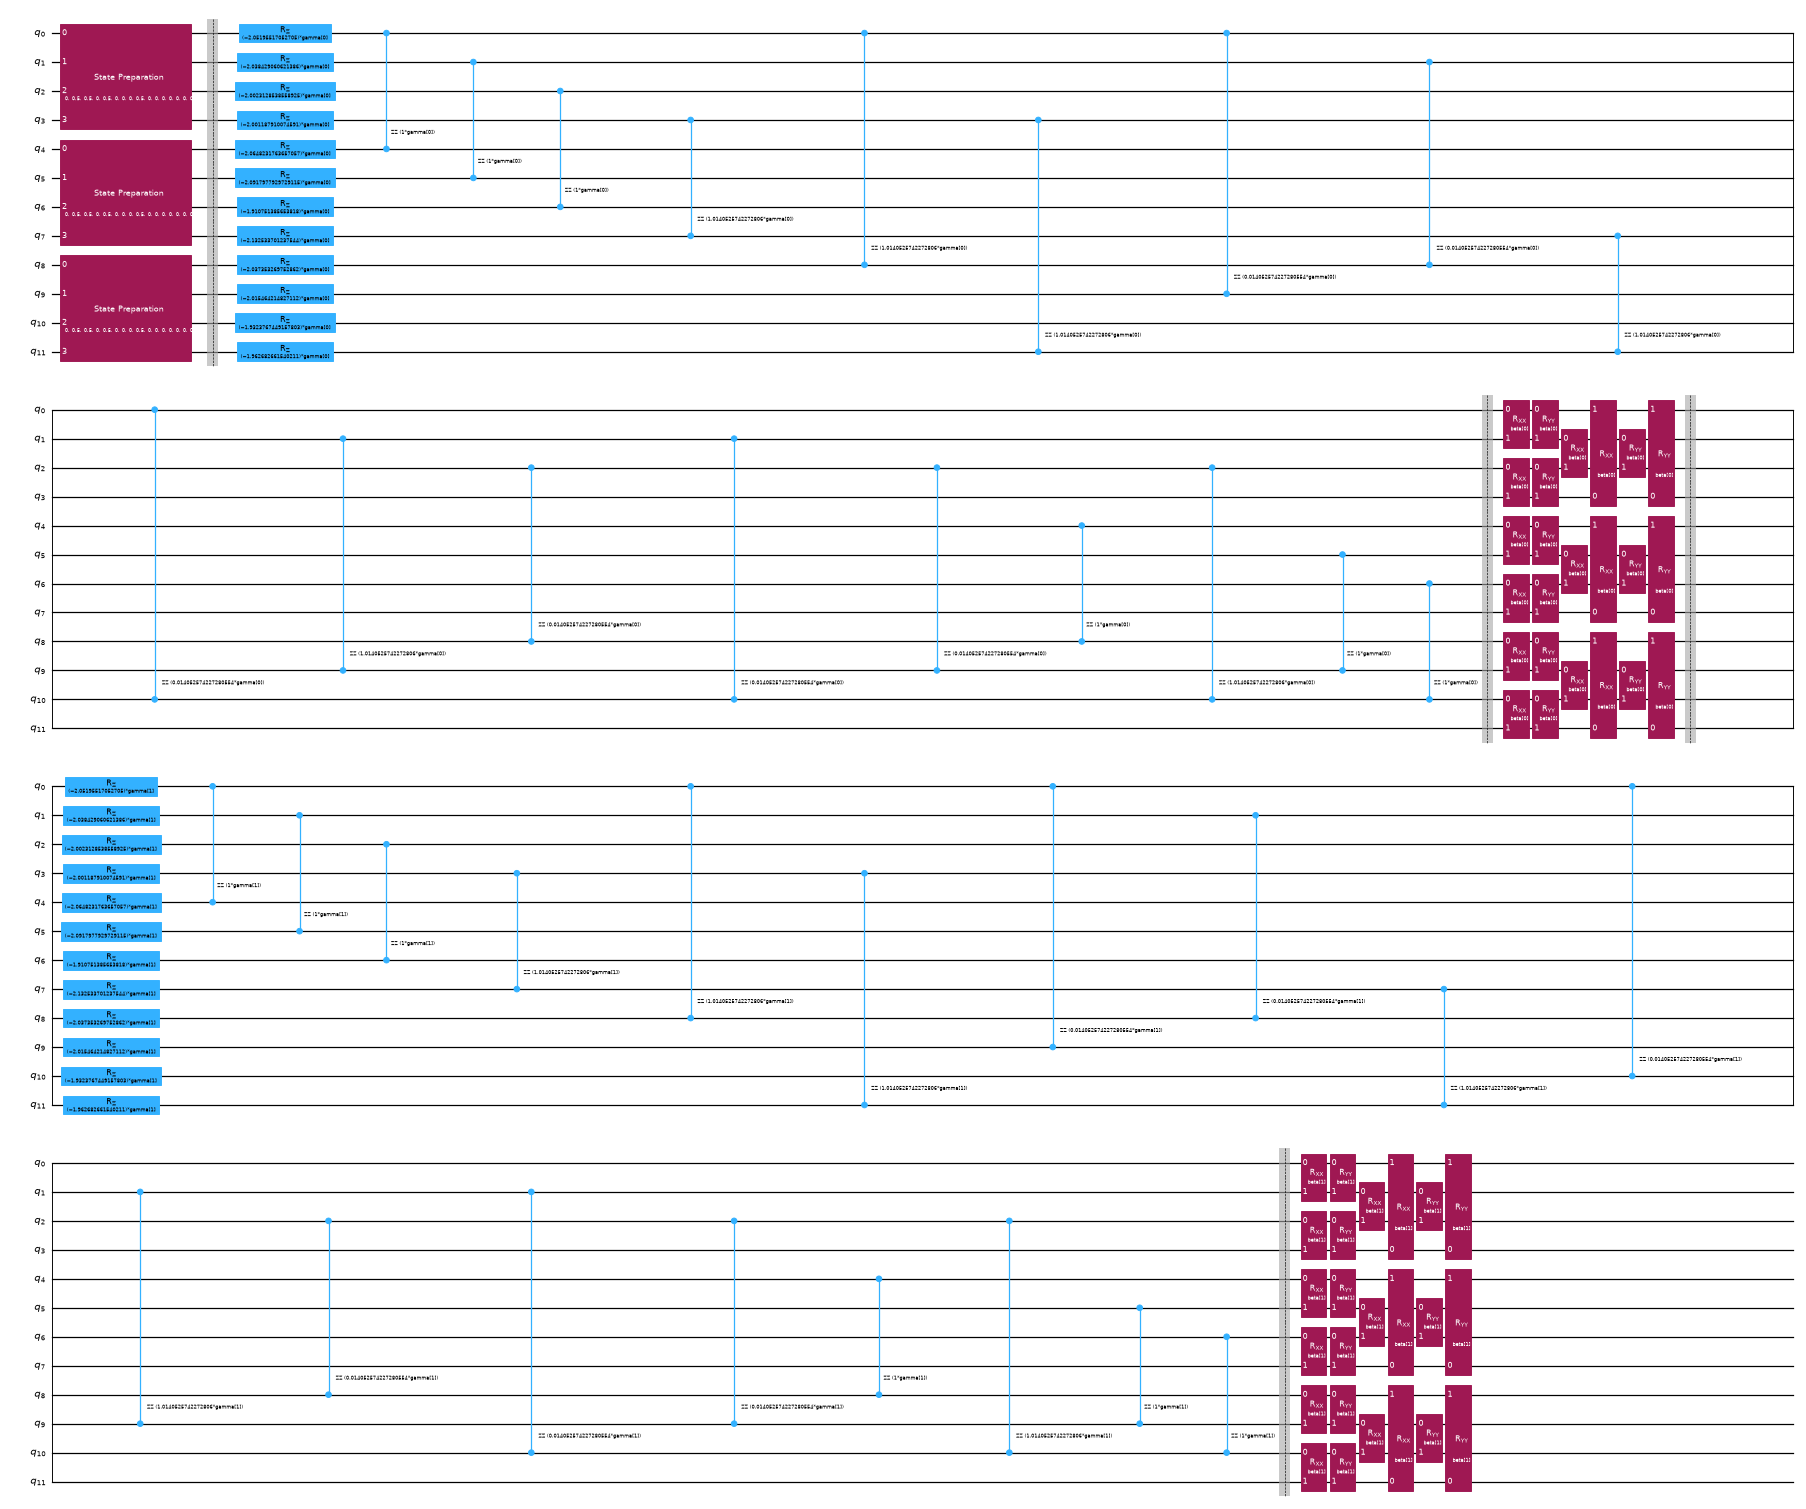

In [5]:
print(runner.circuit.count_ops()); runner.circuit.draw('mpl', fold=60, scale=0.45)

**Limitations:** 12 qubits are trivially brute-forced (no speed-up claimed); synthetic need data on real geography; see `report/FloodQAOA_Report.docx` for depth, penalty and noise studies.